# E14 · Without the atmospheric bands B01 and B09

E13 added spectral indices and lost 0.56 points; AdaBN helped again (+0.28), so the indices carried new train/test
differences. E14 tries the opposite: **remove** the inputs that differ most between EuroSAT (Level-1C, with
atmosphere) and Kaggle (Level-2A, atmosphere removed).

| Band | Wavelength | Measures | Why drop it |
|---|---|---|---|
| B01 | 443 nm | coastal aerosol | mostly atmosphere (aerosols, haze); 60 m |
| B09 | 945 nm | water vapour | mostly atmospheric humidity, not the ground; 60 m |

`05_fourier_analysis` found these two 60 m bands differ the most between train and test, and `02_data_quality` found
SeaLake images with a constant B09. Neither describes the land cover itself, so the model should lose little on
EuroSAT and may transfer better to Kaggle.

Everything else is the **E09a setup** (best model, 72.67%): EfficientNet-B0, `hist_split`, contrast augmentation,
round-3 pseudo-labels (E06c + AdaBN teacher, 8 views agree, SeaLake capped at 400, used 2× per epoch). One change:
10 bands instead of 12.

The teacher (E06c) and the reference (E09a) were trained on 12 bands, so their predictions are made on the 12-band
Kaggle images first (section 2); only the training uses 10 bands.

**Train or load.** `LOAD_RUNS["E14a"] = None` trains. After training, set it to the new run folder and commit the
weights if the run is submitted (`git add -f runs/<run>/model.pt`).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, load_test
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views, to_device_images
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E14_no_atmospheric_bands"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E14a": None,
}
DROP_BANDS = ["B01", "B09"]
REFERENCE = "pl_r3_view_agree_contrast_aug_hist_split_effb0"               # E09a, no AdaBN, 72.67%
R3_TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN: round-3 labels
CAPS = {"SeaLake": 400}        # as in E09a
REPEAT = 2                     # as in E09a
MODEL = "efficientnet_b0"
BANDS = [b for b in TEST_BANDS if b not in DROP_BANDS]   # 10 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
print(f"Bands ({len(BANDS)}):", BANDS)
results = {}                        # variant -> RunResult, compared at the end


def base_config(variant, run_name, description, extra):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", **extra}

Device: Apple GPU (MPS)
Bands (10): ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12']


## 2 · Teacher and reference predictions on the 12-band Kaggle images

Kaggle images are never corrected, so the 12-band set is just the raw test set. The round-3 pseudo-labels are the same
as E09a's; E09a's own predictions are kept for the comparison in section 4.

In [2]:
X_kg12, _ = load_test()
kg12 = SimpleNamespace(kg_images=to_device_images(np.asarray(X_kg12), device))

table, _ = teacher_predictions(R3_TEACHER, kg12, device)
hard_idx = select_view_agree(table, CAPS, SEED)
print(f"{len(hard_idx):,} pseudo-labels (E09a: 2,948)")

ref_dir = find_run(REFERENCE)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, kg12.kg_images, r_norm)
ref_prob = ref_views.mean(0)

del kg12, X_kg12, r_model
if device.type == "mps":
    torch.mps.empty_cache()

2,948 pseudo-labels (E09a: 2,948)


## 3 · E14a · E09a with 10 bands (no B01, B09)

In [3]:
data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)

if LOAD_RUNS["E14a"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E14a"], device)
    best_state = None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E14a"] = finish_run(model, normalizer, history, best_state, data, variant="E14a", load_run=LOAD_RUNS["E14a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E14a", "no_b01_b09_pl_r3_view_agree_contrast_aug_hist_split_effb0",
                       "E09a without the atmospheric bands B01 and B09 (10 bands)",
                       {"dropped_bands": DROP_BANDS,
                        "pseudo_labels": {"teacher": R3_TEACHER, "selection": "view_agree", "caps": CAPS,
                                          "repeat": REPEAT, "n_images": int(len(hard_idx))}}))
del tr_images, tr_labels

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232
Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.8% of the training set, 24,796 images)
epoch  1  train loss 1.468 acc 0.601  val loss 0.318 acc 0.922 *  val_conf 0.825  kg_conf 0.727  kg_sealake 0.239  kg_share_AnnualCrop 0.098  kg_share_Forest 0.150  kg_share_HerbaceousVegetation 0.070  kg_share_Highway 0.085  kg_share_Industrial 0.063  kg_share_Pasture 0.078  kg_share_PermanentCrop 0.078  kg_share_Residential 0.090  kg_share_River 0.049  kg_share_SeaLake 0.239  (55s)
epoch  2  train loss 0.723 acc 0.915  val loss 0.195 acc 0.960 *  val_conf 0.882  kg_conf 0.812  kg_sealake 0.242  kg_share_AnnualCrop 0.063  kg_share_Forest 0.147  kg_share_HerbaceousVegetation 0.071  kg_share_Highway 0.082  kg_share_Industrial 0.051  kg_share_Pasture 0.066  kg_share_PermanentCrop 0.120  kg_share_Residential 0.099  kg_share_River 0.059  kg_share_SeaLake 0.242  (45s)
epoch  3  train loss 0.643 acc 0.948  val loss 0.178 acc 0.965 *

## 4 · Comparison with E09a

`compare_variants` measures E14a's Kaggle confidence and view agreement **with AdaBN**; the E09a row is filled with
both versions so the rows can be compared like for like.

In [4]:
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((ref_dir / "metrics.json").read_text())
ada_dir = find_run("adabn_balanced_" + REFERENCE)
summary.loc["E09a (no AdaBN)"] = {"description": "best model", "internal test (%)": r_metrics["internal_test_acc"] * 100,
                                  "confidence (%)": ref_prob.max(1).mean() * 100,
                                  "view agreement (%)": view_agreement(ref_views) * 100,
                                  "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)}
a_metrics = json.loads((ada_dir / "metrics.json").read_text())
summary.loc["E09a (AdaBN)"] = {"description": "best model + AdaBN", "internal test (%)": np.nan,
                               "confidence (%)": a_metrics["kaggle_mean_confidence"] * 100,
                               "view agreement (%)": a_metrics["kaggle_view_agreement"] * 100,
                               "same class as E09a (%)": np.nan, "Kaggle public (%)": kaggle_score(ada_dir)}
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%)
E14a,E09a without the atmospheric bands B01 and B09...,98.419753,84.625748,88.161626,94.588847,None
E09a (no AdaBN),best model,98.864198,87.362061,90.500945,100.0,72.671
E09a (AdaBN),best model + AdaBN,NaN,85.016817,88.657845,NaN,71.782


In [5]:
# Different predictions: E09a's class (rows) -> E14a's class (no AdaBN) (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.kg_prob.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E14a: 175 images differ from E09a (4.1%)


E14a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E09a,,,,,,,,,,
AnnualCrop,0,0,1,6,0,8,16,0,3,0
Forest,0,0,10,1,0,12,0,0,2,0
HerbaceousVegetation,0,14,0,0,1,3,2,3,3,0
Highway,0,0,1,0,3,1,2,4,0,0
Industrial,1,0,2,2,0,1,1,6,1,0
Pasture,3,0,1,0,1,0,1,1,2,0
PermanentCrop,9,5,2,3,2,20,0,3,0,0
Residential,0,1,0,0,3,2,2,0,0,0
River,0,0,1,0,0,0,0,0,0,1


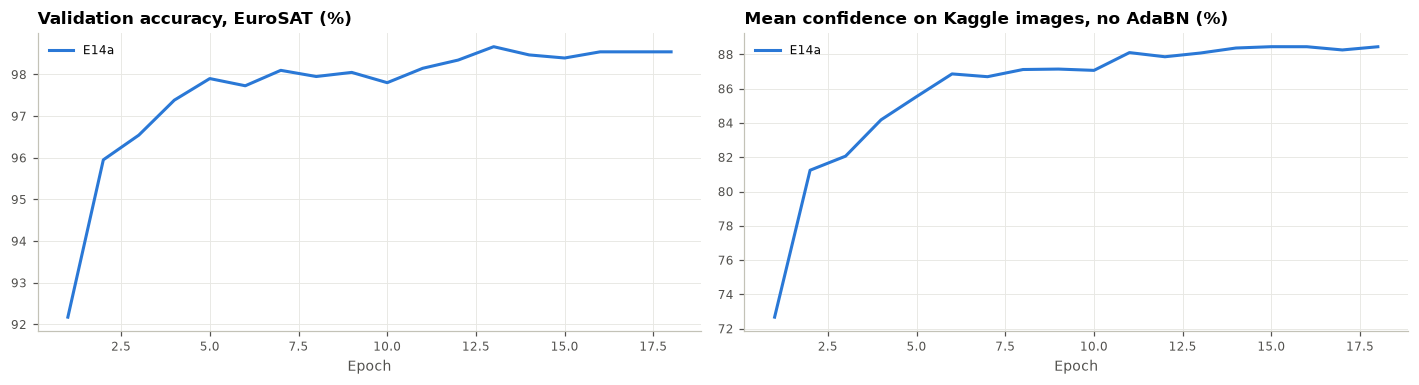

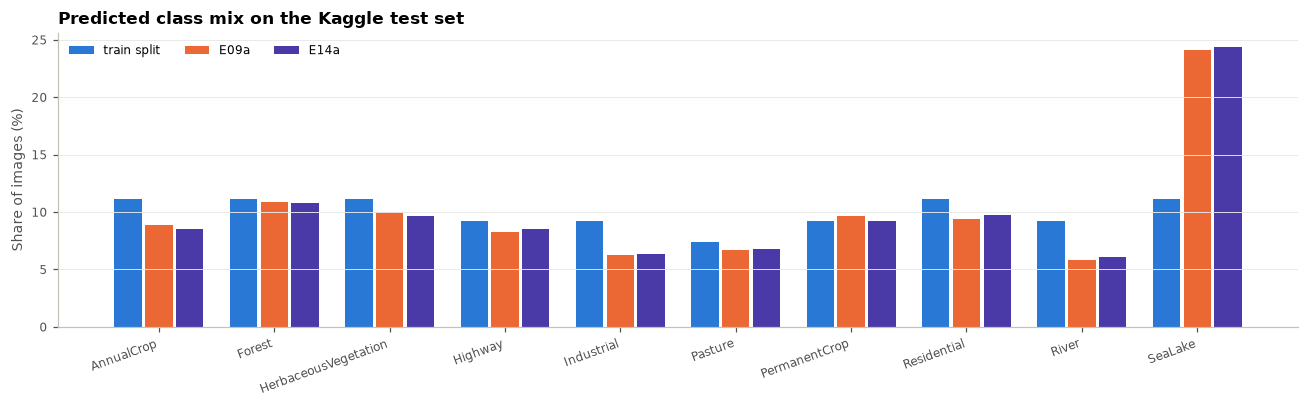

In [6]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

*To fill in after the Kaggle submission (both files: with and without AdaBN).*

| Model | Input | Internal test | Kaggle public (no AdaBN / AdaBN) |
|---|---|---|---|
| E09a | 12 bands | 98.86% | **72.67%** / 71.78% |
| E13a | 12 bands + 5 indices | 98.89% | 71.83% / 72.11% |
| E14a | 10 bands (no B01, B09) | | |